# Step 02 - Modelling 
**UTS Deep Learning - Klasifikasi Citra Makanan Khas Yogyakarta (Bakpia, Gudeg, Sate Klathak)**

**Alur:**
1. Konfigurasi dan seed
2. Membaca **data/split**
3. Layer Augmentasi dan contoh visualnya
4. Training Custom CNN (Custom CNN 4 blok konvolusi + Global Average Pooling + Dense(64) + Dropout(0.5), ±249 ribu parameter)
5. Membangun MobileNetV2 (pretrained ImageNet, bekukan lalu fine-tuning)
6. Pembekuan Backbone
7. Fine tuning
8. Evaluasi (Grafik loss, accuracy, confusion matrix, accuracy, precision, recall, F1, tabel perbandingan)
9. Contoh prediksi benar/salah
10. Simpan model
11. Bahan pertanyaaan analisis  

## STEP - 0 Import Library dan Konfigurasi 

In [11]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)       # mengatur seed random, numpy, dan tensorflow

# ---------- Lokasi folder ----------
ROOT     = Path("..").resolve()
SPLIT    = ROOT / "data" / "split"
MANIFEST = ROOT / "outputs" / "cleaning" / "manifest.csv"
OUT      = ROOT / "outputs" / "modelling"
OUT.mkdir(parents=True, exist_ok=True)

# ---------- Data ----------
IMG_SIZE   = (224, 224)
BATCH_SIZE = 16

# ---------- Model 1: Custom CNN ----------
EPOCHS_CNN   = 120
LR_CNN       = 1e-3
DROPOUT_CNN  = 0.5
PATIENCE_CNN = 15

# ---------- Model 2: MobileNetV2 ----------
DROPOUT_TL   = 0.2
EPOCHS_HEAD, LR_HEAD = 30, 1e-3      # fase 1: backbone beku
EPOCHS_FT,   LR_FT   = 30, 1e-5      # fase 2: fine-tuning
FINE_TUNE_AT = 100                   # layer ke-100 dst. ikut dilatih di fase 2
PATIENCE_TL  = 8                     # EarlyStopping (per fase)
LR_PATIENCE_TL = 4                   # ReduceLROnPlateau (per fase)

print("TensorFlow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "tidak ada -> memakai CPU")
print("Data       :", SPLIT, "| ada?", SPLIT.exists())
print("Manifest   :", MANIFEST.exists())

TensorFlow : 2.21.0
GPU        : tidak ada -> memakai CPU
Data       : D:\Kuliah\Semester 5\Deep Learning\UTS\data\split | ada? True
Manifest   : True


Found 268 files belonging to 3 classes.


Found 59 files belonging to 3 classes.
Found 61 files belonging to 3 classes.

Kelas (label 0, 1, 2): ['bakpia', 'gudeg', 'sate_klathak']
              train  val  test
bakpia           83   21    21
gudeg            90   14    20
sate_klathak     95   24    20
total           268   59    61

Bentuk 1 batch : (16, 224, 224, 3) | label: (16,)
Rentang piksel : 0.0 - 255.0
Contoh label   : [1 0 2 2 2 2 0 1]


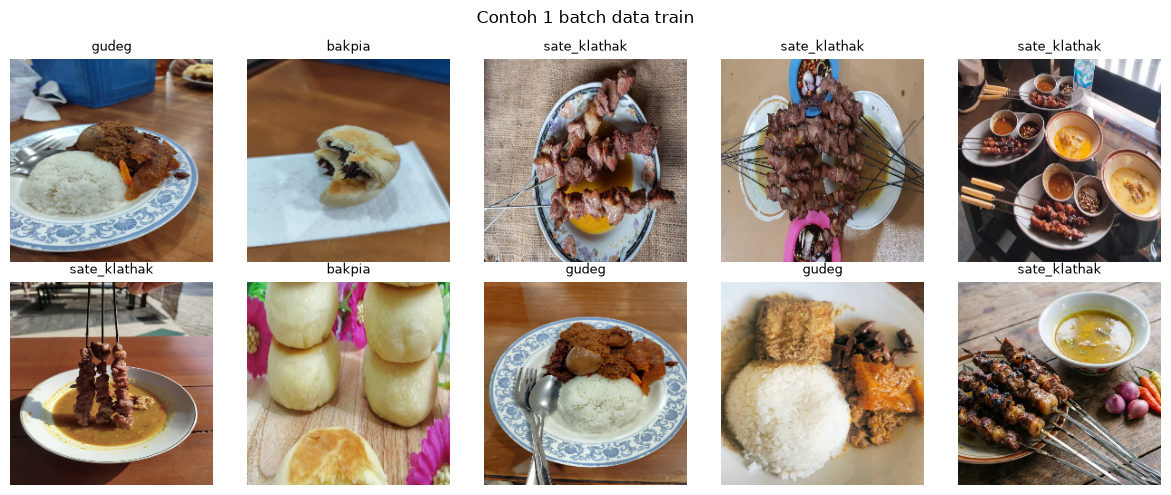

In [7]:
def load_split(name, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        str(SPLIT / name),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",          # label 0, 1, 2
        shuffle=shuffle,
        seed=SEED,
    )

train_raw = load_split("train", shuffle=True)
val_raw   = load_split("val",   shuffle=False)
test_raw  = load_split("test",  shuffle=False)

CLASS_NAMES = train_raw.class_names
assert val_raw.class_names == CLASS_NAMES and test_raw.class_names == CLASS_NAMES, "Urutan kelas beda antar split!"
NUM_CLASSES = len(CLASS_NAMES)
TEST_FILES = [Path(p).name for p in test_raw.file_paths]      # urutan = urutan prediksi nanti

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.prefetch(AUTOTUNE)                 # tidak di-cache supaya diacak ulang tiap epoch
val_ds   = val_raw.cache().prefetch(AUTOTUNE)
test_ds  = test_raw.cache().prefetch(AUTOTUNE)

jumlah = pd.DataFrame({name: pd.Series([Path(p).parent.name for p in ds.file_paths]).value_counts()
                       for name, ds in [("train", train_raw), ("val", val_raw), ("test", test_raw)]})
jumlah.loc["total"] = jumlah.sum()
print("\nKelas (label 0, 1, 2):", CLASS_NAMES)
print(jumlah)

x, y = next(iter(train_ds))
print("\nBentuk 1 batch :", tuple(x.shape), "| label:", tuple(y.shape))
print("Rentang piksel :", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))
print("Contoh label   :", y.numpy()[:8])

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(y[i])], fontsize=9); plt.axis("off")
plt.suptitle("Contoh 1 batch data train")
plt.tight_layout(); plt.show()

## 2. Augmentasi data (hanya untuk train)
Augmentasi dibuat sebagai layer Keras yang diletakkan di awal kedua model.
Layer ini hanya aktif saat `fit()` (training=True) dan otomatis mati saat
`evaluate()` / `predict()`, sehingga data val dan test tidak pernah diaugmentasi.

| Layer | Nilai | Tujuan |
|---|---|---|
| RandomFlip | horizontal | foto makanan tetap sama walau dicerminkan |
| RandomRotation | 0.1 (±36°) | variasi sudut kamera |
| RandomZoom | 0.15 | variasi jarak kamera |
| RandomContrast | 0.15 | variasi pencahayaan |

Perubahan piksel maksimum saat training=False : 0.0
Perubahan piksel maksimum saat training=True  : 255.0


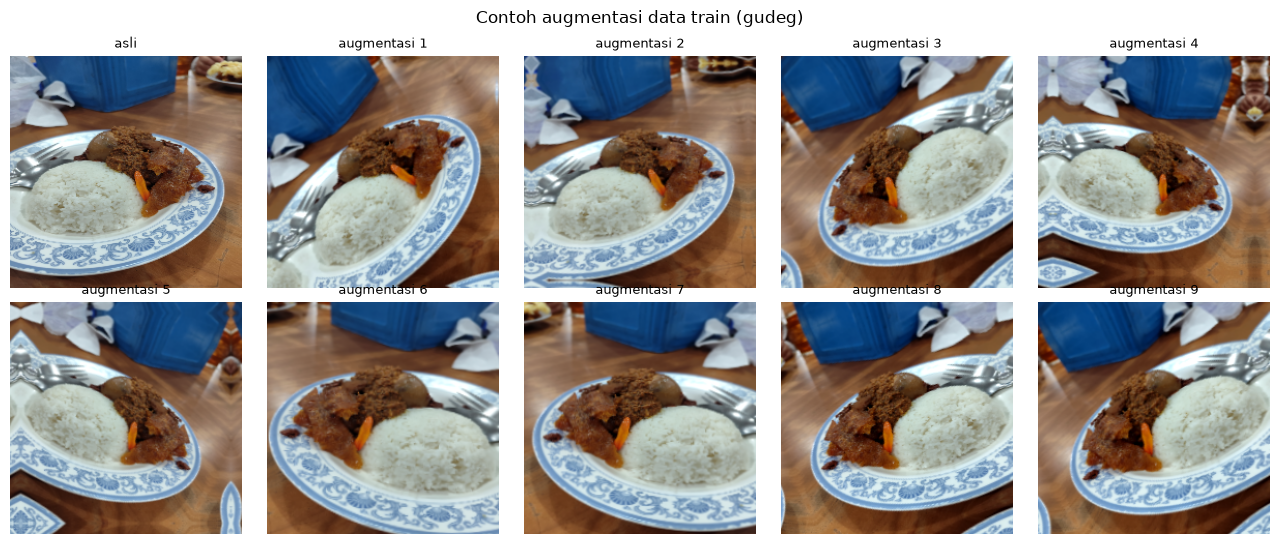

In [8]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),      # cermin kiri-kanan
    tf.keras.layers.RandomRotation(0.1),           # putar acak maks 0.1 x 360° = ±36°
    tf.keras.layers.RandomZoom(0.15),              # perbesar/perkecil acak maks 15%
    tf.keras.layers.RandomContrast(0.15),          # ubah kontras acak maks 15%
], name="augmentasi")

img = x[:1]                                        # ambil 1 foto dari batch langkah 1

# Bukti: saat bukan training (training=False), augmentasi tidak mengubah apa pun
beda_eval  = float(tf.reduce_max(tf.abs(data_augmentation(img, training=False) - img)))
beda_train = float(tf.reduce_max(tf.abs(data_augmentation(img, training=True) - img)))
print(f"Perubahan piksel maksimum saat training=False : {beda_eval}")
print(f"Perubahan piksel maksimum saat training=True  : {beda_train:.1f}")

plt.figure(figsize=(13, 5.5))
plt.subplot(2, 5, 1)
plt.imshow(img[0].numpy().astype("uint8")); plt.title("asli", fontsize=9); plt.axis("off")
for i in range(9):
    aug = data_augmentation(img, training=True)
    plt.subplot(2, 5, i + 2)
    plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8"))
    plt.title(f"augmentasi {i + 1}", fontsize=9); plt.axis("off")
plt.suptitle(f"Contoh augmentasi data train ({CLASS_NAMES[int(y[0])]})")
plt.tight_layout(); plt.savefig(OUT / "contoh_augmentasi.png", dpi=150); plt.show()

## 3. Model 1: Custom CNN (dilatih dari nol)
Dikembangkan berdasarkan code dari model challenge Practice Lab 3 (Conv–MaxPool + Dense(64) + Dropout(0.5)),
disesuaikan untuk citra berwarna 224×224:
- 4 blok Conv 3×3 (32-64-128-128) + MaxPool 2×2, sehingga ukuran turun 224 → 14
- GlobalAveragePooling2D menggantikan Flatten (parameter 249 ribu vs ±1,85 juta)
- Augmentasi dan Rescaling(1/255) berada di dalam model

In [9]:
def build_custom_cnn(dropout_rate=DROPOUT_CNN):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=IMG_SIZE + (3,)),
        data_augmentation,                                   # aktif hanya saat training
        tf.keras.layers.Rescaling(1.0 / 255),                # piksel 0-255 => 0-1 seperti Lab 3

        tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),                # 224 -> 112
        tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),                # 112 -> 56
        tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),                # 56 -> 28
        tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),                # 28 -> 14

        tf.keras.layers.GlobalAveragePooling2D(),            # 14x14x128 -> 128
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="custom_cnn")
    return model

cnn_model = build_custom_cnn()
cnn_model.summary()

# Cek awal sebelum training: 1 batch masuk -> 3 probabilitas per foto
probs = cnn_model(x, training=False).numpy()
loss0 = tf.keras.losses.sparse_categorical_crossentropy(y, probs).numpy().mean()
print("Bentuk output       :", probs.shape)
print("Jumlah probabilitas :", probs[0].round(3), "-> total", probs[0].sum().round(3))
print(f"Loss awal (belum dilatih): {loss0:.3f}  | tebakan acak 3 kelas = ln(3) = {np.log(3):.3f}")
print("Jumlah parameter    :", f"{cnn_model.count_params():,}")

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentasi (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,283 (973.76 KB)

 Trainable params: 249,283 (973.76 KB)

 Non-trainable params: 0 (0.00 B)

Bentuk output       : (16, 3)
Jumlah probabilitas : [0.339 0.328 0.333] -> total 1.0
Loss awal (belum dilatih): 1.100  | tebakan acak 3 kelas = ln(3) = 1.099
Jumlah parameter    : 249,283


## 4. Training Custom CNN
- Optimizer Adam (lr 1e-3) dan loss sparse_categorical_crossentropy, sama seperti Practice Lab 3
- Maksimal 120 epoch dengan tiga callback:
  - **EarlyStopping**: berhenti jika val_loss tidak membaik 15 epoch, lalu kembali ke bobot terbaik
  - **ReduceLROnPlateau**: learning rate dibagi 2 jika val_loss tidak membaik 6 epoch (minimum 1e-5)
  - **ModelCheckpoint**: menyimpan model dengan val_loss terbaik ke file `.keras`
- Pemilihan epoch terbaik hanya berdasarkan **validation**, test tidak disentuh

**Catatan penyesuaian (berdasarkan validation):**
| Run | Epoch maks | Patience ES / LR | Berhenti | Epoch terbaik | val_loss | val acc |
|---|---|---|---|---|---|---|
| 1 | 60 | 10 / 4 | 60 (batas) | 60 → belum konvergen | 0,302 | 0,881 |
| 2 (dipakai) | 120 | 15 / 6 | 85 (EarlyStopping) | 70 | 0,192 | 0,932 |

In [10]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_CNN),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_cnn = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_CNN,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6,
                                         min_lr=1e-5, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(str(OUT / "custom_cnn_best.keras"), monitor="val_loss",
                                       save_best_only=True),
]

t0 = time.time()
history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    callbacks=callbacks_cnn,
    verbose=2,
)
time_cnn = time.time() - t0

hist_cnn = pd.DataFrame(history_cnn.history)
hist_cnn.index = hist_cnn.index + 1                     # epoch mulai dari 1
hist_cnn.index.name = "epoch"
hist_cnn.to_csv(OUT / "history_custom_cnn.csv")

best_ep = int(hist_cnn.val_loss.idxmin())
print(f"\nEpoch dijalankan : {len(hist_cnn)} (maks {EPOCHS_CNN})")
print(f"Epoch terbaik    : {best_ep} (val_loss terendah = {hist_cnn.val_loss[best_ep]:.4f})")
print(f"Pada epoch itu   : train acc {hist_cnn.accuracy[best_ep]:.3f} | val acc {hist_cnn.val_accuracy[best_ep]:.3f}")
print(f"Waktu training   : {time_cnn:.1f} detik ({time_cnn/60:.1f} menit)")

Epoch 1/120


d:\Kuliah\Semester 5\Deep Learning\UTS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


17/17 - 4s - 265ms/step - accuracy: 0.3507 - loss: 1.1041 - val_accuracy: 0.4068 - val_loss: 1.0737 - learning_rate: 0.0010
Epoch 2/120
17/17 - 3s - 191ms/step - accuracy: 0.3955 - loss: 1.0608 - val_accuracy: 0.6271 - val_loss: 0.9235 - learning_rate: 0.0010
Epoch 3/120
17/17 - 3s - 185ms/step - accuracy: 0.4776 - loss: 1.0156 - val_accuracy: 0.3729 - val_loss: 1.1434 - learning_rate: 0.0010
Epoch 4/120
17/17 - 3s - 185ms/step - accuracy: 0.4888 - loss: 0.9996 - val_accuracy: 0.7119 - val_loss: 0.9494 - learning_rate: 0.0010
Epoch 5/120
17/17 - 3s - 181ms/step - accuracy: 0.6157 - loss: 0.9202 - val_accuracy: 0.7119 - val_loss: 0.8514 - learning_rate: 0.0010
Epoch 6/120
17/17 - 3s - 173ms/step - accuracy: 0.6306 - loss: 0.8509 - val_accuracy: 0.7288 - val_loss: 0.8893 - learning_rate: 0.0010
Epoch 7/120
17/17 - 3s - 175ms/step - accuracy: 0.5672 - loss: 0.8367 - val_accuracy: 0.5085 - val_loss: 0.9219 - learning_rate: 0.0010
Epoch 8/120
17/17 - 3s - 179ms/step - accuracy: 0.5858 - los

## Eksperimen: pengaruh Dropout pada Custom CNN
Meniru eksperimen dropout Practice Lab 3 (0.0 / 0.3 / 0.5).
Setiap rate dilatih ulang dari nol dengan pengaturan yang sama dengan model utama
(seed, Adam 1e-3, maks 120 epoch, EarlyStopping 15, ReduceLROnPlateau 6).
Perbandingan **hanya memakai validation**. Model utama (`cnn_model`, `custom_cnn_best.keras`) tidak diubah.


========== Dropout 0.0 ==========


d:\Kuliah\Semester 5\Deep Learning\UTS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'dropout': 0.0, 'epoch_dijalankan': 80, 'epoch_terbaik': 65, 'val_loss': 0.2697, 'val_acc': 0.9153, 'train_acc': 0.9627, 'train_loss': 0.1278, 'gap_acc (train-val)': 0.0474, 'waktu_detik': 259.9}

========== Dropout 0.3 ==========


d:\Kuliah\Semester 5\Deep Learning\UTS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'dropout': 0.3, 'epoch_dijalankan': 52, 'epoch_terbaik': 37, 'val_loss': 0.2938, 'val_acc': 0.8644, 'train_acc': 0.9067, 'train_loss': 0.2628, 'gap_acc (train-val)': 0.0423, 'waktu_detik': 162.4}

========== Dropout 0.5 ==========


d:\Kuliah\Semester 5\Deep Learning\UTS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'dropout': 0.5, 'epoch_dijalankan': 65, 'epoch_terbaik': 50, 'val_loss': 0.2483, 'val_acc': 0.9322, 'train_acc': 0.9067, 'train_loss': 0.2626, 'gap_acc (train-val)': -0.0255, 'waktu_detik': 195.6}

Tabel eksperimen dropout (dipilih berdasarkan val_loss terendah):


,epoch_dijalankan,epoch_terbaik,val_loss,val_acc,train_acc,train_loss,gap_acc (train-val),waktu_detik
dropout,,,,,,,,
0.0,80,65,0.2697,0.9153,0.9627,0.1278,0.0474,259.9
0.3,52,37,0.2938,0.8644,0.9067,0.2628,0.0423,162.4
0.5,65,50,0.2483,0.9322,0.9067,0.2626,-0.0255,195.6


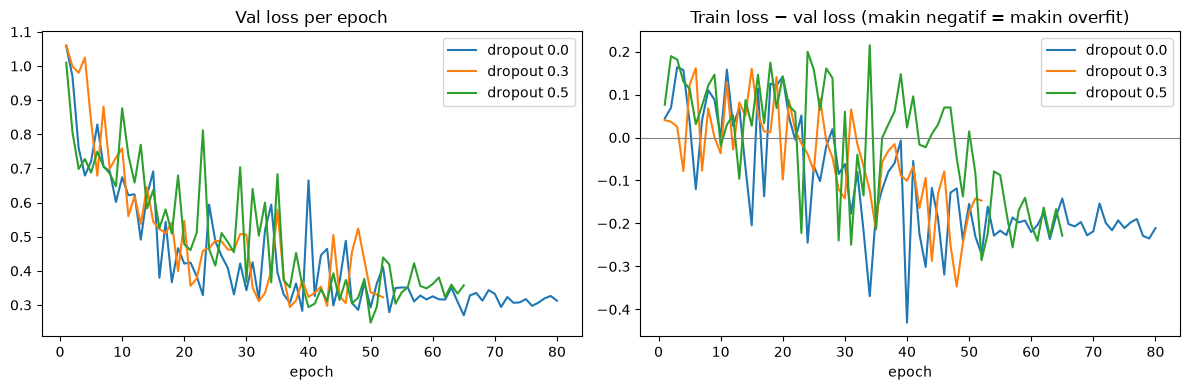

In [15]:
DROPOUT_RATES = [0.0, 0.3, 0.5]
exp_results, exp_histories = [], {}

for rate in DROPOUT_RATES:
    print(f"\n========== Dropout {rate} ==========")
    tf.keras.utils.set_random_seed(SEED)                     # bobot awal sama untuk setiap rate
    exp_model = build_custom_cnn(dropout_rate=rate)          # model BARU, bukan cnn_model
    exp_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR_CNN),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    exp_callbacks = [                                        # tanpa ModelCheckpoint -> file model utama aman
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_CNN, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5),  # sama dengan langkah 4
    ]
    t0 = time.time()
    h = exp_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN,
                      callbacks=exp_callbacks, verbose=0)    # verbose=0: tidak mencetak per epoch
    elapsed = time.time() - t0

    eh = pd.DataFrame(h.history); eh.index = eh.index + 1; eh.index.name = "epoch"
    eh.to_csv(OUT / f"history_dropout_{rate}.csv")
    exp_histories[rate] = eh
    b = int(eh.val_loss.idxmin())
    exp_results.append({
        "dropout": rate,
        "epoch_dijalankan": len(eh),
        "epoch_terbaik": b,
        "val_loss": round(float(eh.val_loss[b]), 4),
        "val_acc": round(float(eh.val_accuracy[b]), 4),
        "train_acc": round(float(eh.accuracy[b]), 4),
        "train_loss": round(float(eh.loss[b]), 4),
        "gap_acc (train-val)": round(float(eh.accuracy[b] - eh.val_accuracy[b]), 4),
        "waktu_detik": round(elapsed, 1),
    })
    print(exp_results[-1])
    del exp_model                                            # bebaskan memori sebelum rate berikutnya

tabel_dropout = pd.DataFrame(exp_results).set_index("dropout")
tabel_dropout.to_csv(OUT / "eksperimen_dropout.csv")
print("\nTabel eksperimen dropout (dipilih berdasarkan val_loss terendah):")
display(tabel_dropout)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for rate, eh in exp_histories.items():
    ax[0].plot(eh.index, eh.val_loss, label=f"dropout {rate}")
    ax[1].plot(eh.index, eh.loss - eh.val_loss, label=f"dropout {rate}")
ax[0].set_title("Val loss per epoch"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_title("Train loss − val loss (makin negatif = makin overfit)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "eksperimen_dropout.png", dpi=150); plt.show()

## Eksperimen: strategi training (learning rate tetap vs callback)
Membuktikan manfaat EarlyStopping dan ReduceLROnPlateau pada Custom CNN (dropout 0.5, seed sama):
- **A.** LR tetap 1e-3, tanpa callback, 120 epoch penuh, model yang dipakai = epoch terakhir
- **B.** LR tetap 1e-3 + EarlyStopping (tanpa penurunan LR)
- **Model utama**: LR turun (ReduceLROnPlateau) + EarlyStopping (hasil langkah 4, tidak dilatih ulang)
Perbandingan hanya memakai validation.


========== A. LR tetap, tanpa callback ==========


d:\Kuliah\Semester 5\Deep Learning\UTS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


selesai: 120 epoch, 381 detik

========== B. LR tetap + EarlyStopping ==========


d:\Kuliah\Semester 5\Deep Learning\UTS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


selesai: 100 epoch, 326 detik


,epoch_dijalankan,epoch_terbaik,val_loss_terbaik,epoch_model_dipakai,val_loss_model,val_acc_model,train_loss_model,waktu_detik
konfigurasi,,,,,,,,
"A. LR tetap, tanpa callback",120,120,0.1798,120,0.1798,0.9661,0.0890,381.0
B. LR tetap + EarlyStopping,100,85,0.1653,85,0.1653,0.9322,0.1396,326.3
Model utama (LR turun + EarlyStopping),85,70,0.1917,70,0.1917,0.9322,0.2613,251.3


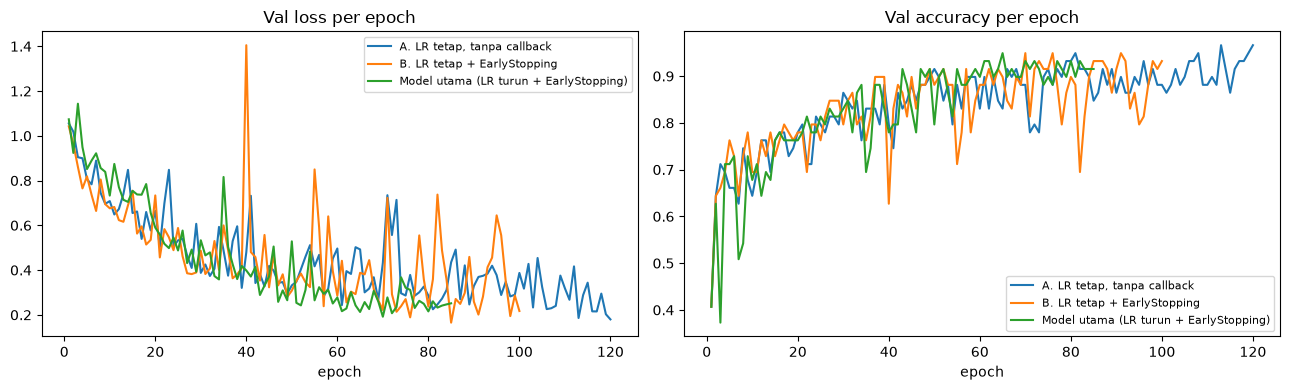

In [ ]:
# jaga-jaga jika kernel sempat restart: ambil history model utama dari file
if "hist_cnn" not in globals():
    hist_cnn = pd.read_csv(OUT / "history_custom_cnn.csv", index_col="epoch")
if "time_cnn" not in globals():
    time_cnn = float("nan")

LR_EXPERIMENTS = {
    "A. LR tetap, tanpa callback": dict(early_stop=False, reduce_lr=False),
    "B. LR tetap + EarlyStopping": dict(early_stop=True,  reduce_lr=False),
}
lr_histories, lr_times = {}, {}

for name, cfg in LR_EXPERIMENTS.items():
    print(f"\n========== {name} ==========")
    tf.keras.utils.set_random_seed(SEED)
    lr_model = build_custom_cnn(dropout_rate=DROPOUT_CNN)          # model BARU, dropout 0.5
    lr_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR_CNN),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = []
    if cfg["early_stop"]:
        cbs.append(tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_CNN,
                                                    restore_best_weights=True))
    if cfg["reduce_lr"]:
        cbs.append(tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                                        patience=6, min_lr=1e-5))
    t0 = time.time()
    h = lr_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN, callbacks=cbs, verbose=0)
    lr_times[name] = time.time() - t0
    eh = pd.DataFrame(h.history); eh.index = eh.index + 1; eh.index.name = "epoch"
    eh.to_csv(OUT / f"history_lr_{name[0]}.csv")
    lr_histories[name] = eh
    print(f"selesai: {len(eh)} epoch, {lr_times[name]:.0f} detik")
    del lr_model

# model utama sebagai pembanding (tidak dilatih ulang)
lr_histories["Model utama (LR turun + EarlyStopping)"] = hist_cnn
lr_times["Model utama (LR turun + EarlyStopping)"] = time_cnn

rows = []
for name, eh in lr_histories.items():
    b = int(eh.val_loss.idxmin())
    pakai_terbaik = not name.startswith("A.")             
    ep_pakai = b if pakai_terbaik else int(eh.index[-1])
    rows.append({
        "konfigurasi": name,
        "epoch_dijalankan": len(eh),
        "epoch_terbaik": b,
        "val_loss_terbaik": round(float(eh.val_loss[b]), 4),
        "epoch_model_dipakai": ep_pakai,
        "val_loss_model": round(float(eh.val_loss[ep_pakai]), 4),
        "val_acc_model": round(float(eh.val_accuracy[ep_pakai]), 4),
        "train_loss_model": round(float(eh.loss[ep_pakai]), 4),
        "waktu_detik": round(lr_times[name], 1),
    })
tabel_lr = pd.DataFrame(rows).set_index("konfigurasi")
tabel_lr.to_csv(OUT / "eksperimen_strategi_training.csv")
display(tabel_lr)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, eh in lr_histories.items():
    ax[0].plot(eh.index, eh.val_loss, label=name)
    ax[1].plot(eh.index, eh.val_accuracy, label=name)
ax[0].set_title("Val loss per epoch"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=8)
ax[1].set_title("Val accuracy per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "eksperimen_strategi_training.png", dpi=150); plt.show()

## 5. Model 2: MobileNetV2 (transfer learning, pretrained ImageNet)
- Backbone MobileNetV2 tanpa classifier ImageNet (`include_top=False`), bobot ImageNet, **dibekukan** untuk fase 1
- Augmentasi sama persis dengan Custom CNN
- Normalisasi ke rentang [-1, 1] sesuai cara MobileNetV2 dilatih di ImageNet
- Backbone dipanggil dengan `training=False` agar BatchNorm tetap memakai statistik ImageNet
- Head baru: GlobalAveragePooling2D → Dropout(0.2) → Dense(3, softmax)

In [12]:
tf.keras.utils.set_random_seed(SEED)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,             # buang classifier 1000 kelas dari ImageNet
    weights="imagenet",
)
base_model.trainable = False       # fase 1: seluruh backbone dibekukan

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
h = data_augmentation(inputs)                                       # augmentasi yang sama dengan Custom CNN
h = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1, name="preprocess_mnv2")(h)   # 0-255 -> -1..1
h = base_model(h, training=False)                                   # BatchNorm backbone tetap mode inferensi
h = tf.keras.layers.GlobalAveragePooling2D()(h)                     # 7x7x1280 -> 1280
h = tf.keras.layers.Dropout(DROPOUT_TL)(h)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(h)
mnv2_model = tf.keras.Model(inputs, outputs, name="mobilenetv2")

mnv2_model.summary()
print("Jumlah layer di backbone MobileNetV2:", len(base_model.layers))

probs = mnv2_model(x, training=False).numpy()
loss0 = tf.keras.losses.sparse_categorical_crossentropy(y, probs).numpy().mean()
print("Bentuk output       :", probs.shape)
print("Jumlah probabilitas :", probs[0].round(3), "-> total", probs[0].sum().round(3))
print(f"Loss awal (belum dilatih): {loss0:.3f}  | tebakan acak 3 kelas = ln(3) = {np.log(3):.3f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess_mnv2 (Rescaling)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Jumlah layer di backbone MobileNetV2: 154
Bentuk output       : (16, 3)
Jumlah probabilitas : [0.241 0.464 0.294] -> total 1.0
Loss awal (belum dilatih): 1.144  | tebakan acak 3 kelas = ln(3) = 1.099


## 6. MobileNetV2 fase 1: feature extraction (backbone beku)
Hanya head (3.843 parameter) yang dilatih, backbone MobileNetV2 tetap memakai bobot ImageNet.
- Adam lr 1e-3, sparse_categorical_crossentropy
- Maksimal 30 epoch; EarlyStopping (patience 8) dan ReduceLROnPlateau (patience 4)
  memakai konfig yang sama seperti Custom CNN: dipantau dari val_loss
- Model terbaik disimpan ke `mobilenetv2_best.keras`

In [13]:
mnv2_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_HEAD),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_head = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_TL,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE_TL,
                                         min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(str(OUT / "mobilenetv2_best.keras"), monitor="val_loss",
                                       save_best_only=True),
]

t0 = time.time()
history_head = mnv2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks_head,
    verbose=2,
)
time_head = time.time() - t0

hist_head = pd.DataFrame(history_head.history)
hist_head.index = hist_head.index + 1
hist_head.index.name = "epoch"
hist_head["fase"] = 1

best_head = int(hist_head.val_loss.idxmin())
best_val_loss_head = float(hist_head.val_loss.min())
head_weights = mnv2_model.get_weights()          # cadangan bobot terbaik fase 1 (dipakai di langkah 7)

print(f"\n[Fase 1] Epoch dijalankan : {len(hist_head)} (maks {EPOCHS_HEAD})")
print(f"[Fase 1] Epoch terbaik    : {best_head} (val_loss = {best_val_loss_head:.4f})")
print(f"[Fase 1] Pada epoch itu   : train acc {hist_head.accuracy[best_head]:.3f} | val acc {hist_head.val_accuracy[best_head]:.3f}")
print(f"[Fase 1] Waktu training   : {time_head:.1f} detik ({time_head/60:.1f} menit)")

Epoch 1/30


d:\Kuliah\Semester 5\Deep Learning\UTS\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


17/17 - 7s - 391ms/step - accuracy: 0.6269 - loss: 0.8680 - val_accuracy: 0.9492 - val_loss: 0.3639 - learning_rate: 0.0010
Epoch 2/30
17/17 - 3s - 162ms/step - accuracy: 0.9142 - loss: 0.3174 - val_accuracy: 1.0000 - val_loss: 0.1741 - learning_rate: 0.0010
Epoch 3/30
17/17 - 3s - 162ms/step - accuracy: 0.9515 - loss: 0.1758 - val_accuracy: 1.0000 - val_loss: 0.1094 - learning_rate: 0.0010
Epoch 4/30
17/17 - 3s - 160ms/step - accuracy: 0.9664 - loss: 0.1273 - val_accuracy: 1.0000 - val_loss: 0.0897 - learning_rate: 0.0010
Epoch 5/30
17/17 - 3s - 162ms/step - accuracy: 0.9813 - loss: 0.0979 - val_accuracy: 0.9831 - val_loss: 0.0838 - learning_rate: 0.0010
Epoch 6/30
17/17 - 3s - 161ms/step - accuracy: 0.9739 - loss: 0.0865 - val_accuracy: 1.0000 - val_loss: 0.0725 - learning_rate: 0.0010
Epoch 7/30
17/17 - 3s - 161ms/step - accuracy: 0.9851 - loss: 0.0633 - val_accuracy: 1.0000 - val_loss: 0.0636 - learning_rate: 0.0010
Epoch 8/30
17/17 - 3s - 161ms/step - accuracy: 0.9888 - loss: 0.05

## 7. MobileNetV2 fase 2: fine-tuning
- Layer backbone ke-100 sampai akhir (54 dari 154 layer) dibuka, layer 0–99 tetap beku
- Learning rate diperkecil 100× menjadi 1e-5 agar fitur ImageNet tidak rusak
- Model di-compile ulang (wajib setelah mengubah `trainable`)
- Bobot fase 2 hanya dipakai jika val_loss-nya lebih baik dari fase 1;
  jika tidak, model kembali ke bobot terbaik fase 1

In [14]:
base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False                            # layer 0-99 tetap beku

n_layer_dibuka = sum(layer.trainable for layer in base_model.layers)
n_param_dilatih = sum(int(np.prod(w.shape)) for w in mnv2_model.trainable_weights)
print(f"Layer backbone yang dibuka : {n_layer_dibuka} dari {len(base_model.layers)} (mulai layer ke-{FINE_TUNE_AT})")
print(f"Parameter yang dilatih     : {n_param_dilatih:,} dari {mnv2_model.count_params():,}")

mnv2_model.compile(                                    # WAJIB compile ulang setelah mengubah trainable
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FT),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_TL,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE_TL,
                                         min_lr=1e-7, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(str(OUT / "mobilenetv2_best.keras"), monitor="val_loss",
                                       save_best_only=True,
                                       initial_value_threshold=best_val_loss_head),   # hanya simpan jika lebih baik dari fase 1
]

start_ep = len(hist_head)
t0 = time.time()
history_ft = mnv2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=start_ep + EPOCHS_FT,
    initial_epoch=start_ep,                            # nomor epoch melanjutkan fase 1
    callbacks=callbacks_ft,
    verbose=2,
)
time_ft = time.time() - t0

hist_ft = pd.DataFrame(history_ft.history)
hist_ft.index = hist_ft.index + start_ep + 1
hist_ft.index.name = "epoch"
hist_ft["fase"] = 2
best_val_loss_ft = float(hist_ft.val_loss.min())

# Pilih bobot akhir berdasarkan val_loss: fase 2 hanya dipakai jika lebih baik dari fase 1
if best_val_loss_ft < best_val_loss_head:
    fase_dipakai = 2
else:
    fase_dipakai = 1
    mnv2_model.load_weights(str(OUT / "mobilenetv2_best.keras"))   # file berisi bobot terbaik fase 1

hist_mnv2 = pd.concat([hist_head, hist_ft])
hist_mnv2.to_csv(OUT / "history_mobilenetv2.csv")
time_mnv2 = time_head + time_ft
best_ep_mnv2 = int(hist_mnv2.val_loss.idxmin())

print(f"\n[Fase 2] Epoch dijalankan : {len(hist_ft)} (maks {EPOCHS_FT})")
print(f"[Fase 2] val_loss terbaik : {best_val_loss_ft:.4f}  (fase 1: {best_val_loss_head:.4f})")
print(f"[Fase 2] Waktu training   : {time_ft:.1f} detik")
print(f"\nBobot akhir MobileNetV2   : fase {fase_dipakai} (epoch {best_ep_mnv2}, val_loss {hist_mnv2.val_loss.min():.4f}, "
      f"val acc {hist_mnv2.val_accuracy[best_ep_mnv2]:.3f})")
print(f"Total waktu training      : {time_mnv2:.1f} detik ({time_mnv2/60:.1f} menit)")

Layer backbone yang dibuka : 54 dari 154 (mulai layer ke-100)
Parameter yang dilatih     : 1,865,283 dari 2,261,827
Epoch 31/60
17/17 - 11s - 670ms/step - accuracy: 0.8321 - loss: 0.4090 - val_accuracy: 1.0000 - val_loss: 0.0286 - learning_rate: 1.0000e-05
Epoch 32/60
17/17 - 4s - 245ms/step - accuracy: 0.9030 - loss: 0.2530 - val_accuracy: 1.0000 - val_loss: 0.0276 - learning_rate: 1.0000e-05
Epoch 33/60
17/17 - 4s - 241ms/step - accuracy: 0.9403 - loss: 0.1458 - val_accuracy: 1.0000 - val_loss: 0.0260 - learning_rate: 1.0000e-05
Epoch 34/60
17/17 - 4s - 241ms/step - accuracy: 0.9478 - loss: 0.1509 - val_accuracy: 1.0000 - val_loss: 0.0254 - learning_rate: 1.0000e-05
Epoch 35/60
17/17 - 5s - 300ms/step - accuracy: 0.9627 - loss: 0.1317 - val_accuracy: 1.0000 - val_loss: 0.0253 - learning_rate: 1.0000e-05
Epoch 36/60
17/17 - 5s - 271ms/step - accuracy: 0.9440 - loss: 0.1336 - val_accuracy: 1.0000 - val_loss: 0.0236 - learning_rate: 1.0000e-05
Epoch 37/60
17/17 - 4s - 262ms/step - accur

## 8. Kurva training, waktu, dan jumlah parameter (belum memakai data testing)
- **Model di Lock**: kedua model terbaik dimuat dari file `.keras` dan dicek ulang di validation.
  Setelah langkah ini, tidak ada perubahan model/hyperparameter lagi.
- Grafik training vs validation accuracy dan loss (ada do ketentuan evaluasi poin 1–2)
- Waktu training dan jumlah parameter (ada diketentuan evaluasi poin 5)

Custom CNN   | val_loss 0.1917 (history terbaik 0.1917) | val acc 0.9322
MobileNetV2  | val_loss 0.0193 (history terbaik 0.0193) | val acc 1.0000


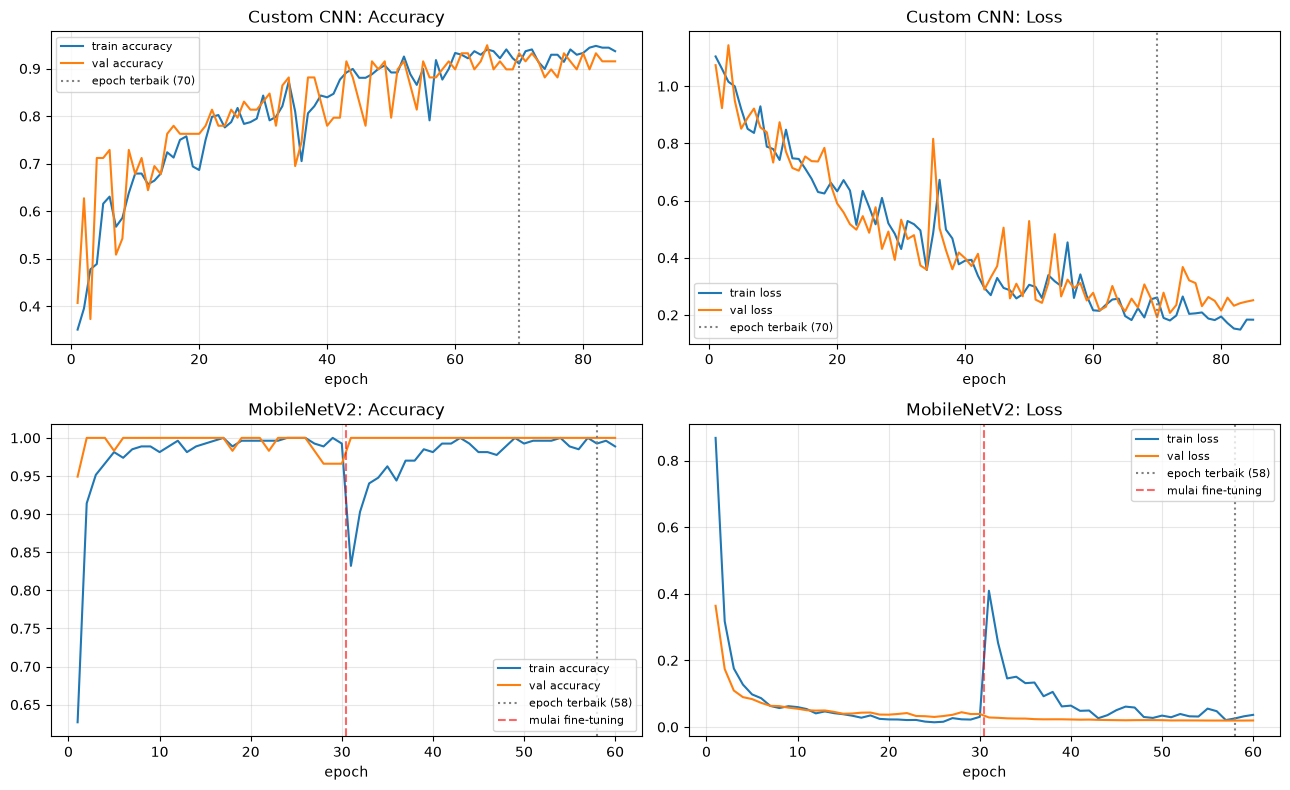

,Custom CNN,MobileNetV2
Total parameter,"249,283","2,261,827"
Parameter dilatih,"249,283 (semua, dari nol)","fase 1: 3,843 | fase 2: 1,865,283"
Epoch dijalankan,85,"60 (fase 1: 30, fase 2: 30)"
Epoch terbaik,70,58
Waktu training (detik),251.3,211.2
Waktu per epoch (detik),2.96,3.52


In [17]:
# 8a. Kunci model: muat model terbaik dari file
cnn_final  = tf.keras.models.load_model(OUT / "custom_cnn_best.keras")
mnv2_final = tf.keras.models.load_model(OUT / "mobilenetv2_best.keras")
MODELS = {"Custom CNN": cnn_final, "MobileNetV2": mnv2_final}

hist = {
    "Custom CNN":  pd.read_csv(OUT / "history_custom_cnn.csv", index_col="epoch"),
    "MobileNetV2": pd.read_csv(OUT / "history_mobilenetv2.csv", index_col="epoch"),
}

# Cek: hasil di val harus sama dengan val_loss terbaik saat training
for name, model in MODELS.items():
    vl, va = model.evaluate(val_ds, verbose=0)
    print(f"{name:12s} | val_loss {vl:.4f} (history terbaik {hist[name].val_loss.min():.4f}) | val acc {va:.4f}")

# 8b. Grafik accuracy dan loss (train vs val)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (name, h) in enumerate(hist.items()):
    best = int(h.val_loss.idxmin())
    for col, (metric, judul) in enumerate([("accuracy", "Accuracy"), ("loss", "Loss")]):
        ax = axes[row, col]
        ax.plot(h.index, h[metric], label=f"train {metric}")
        ax.plot(h.index, h[f"val_{metric}"], label=f"val {metric}")
        ax.axvline(best, color="gray", ls=":", label=f"epoch terbaik ({best})")
        if "fase" in h.columns and (h.fase == 2).any():
            ax.axvline(h.index[h.fase == 2][0] - 0.5, color="red", ls="--", alpha=0.6, label="mulai fine-tuning")
        ax.set_title(f"{name}: {judul}"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "kurva_training.png", dpi=150); plt.show()

# 8c. Waktu training dan jumlah parameter
if "time_cnn" not in globals():  time_cnn = 251.3                    # dari output langkah 4 jika kernel sempat restart
if "time_mnv2" not in globals(): time_mnv2 = 211.2                   # dari output langkah 7
if "n_param_dilatih" not in globals(): n_param_dilatih = 1_865_283   # dari output langkah 7

h_c, h_m = hist["Custom CNN"], hist["MobileNetV2"]
tabel_efisiensi = pd.DataFrame({
    "Custom CNN": {
        "Total parameter": f"{cnn_final.count_params():,}",
        "Parameter dilatih": f"{cnn_final.count_params():,} (semua, dari nol)",
        "Epoch dijalankan": f"{len(h_c)}",
        "Epoch terbaik": f"{int(h_c.val_loss.idxmin())}",
        "Waktu training (detik)": f"{time_cnn:.1f}",
        "Waktu per epoch (detik)": f"{time_cnn / len(h_c):.2f}",
    },
    "MobileNetV2": {
        "Total parameter": f"{mnv2_final.count_params():,}",
        "Parameter dilatih": f"fase 1: {mnv2_final.layers[-1].count_params():,} | fase 2: {n_param_dilatih:,}",
        "Epoch dijalankan": f"{len(h_m)} (fase 1: {(h_m.fase == 1).sum()}, fase 2: {(h_m.fase == 2).sum()})",
        "Epoch terbaik": f"{int(h_m.val_loss.idxmin())}",
        "Waktu training (detik)": f"{time_mnv2:.1f}",
        "Waktu per epoch (detik)": f"{time_mnv2 / len(h_m):.2f}",
    },
})
tabel_efisiensi.to_csv(OUT / "tabel_efisiensi.csv")
display(tabel_efisiensi)

## 9. Evaluasi pada test set (dijalankan hanya SATU KALI)
Kedua model sudah fix di langkah 8. Test set dipakai pertama dan satu-satunya kali di sini.
- Classification report: accuracy, precision, recall, F1 per kelas (ketentuan evaluasi poin 4)
- Confusion matrix kedua model (poin 3)
- Rincian akurasi per asal foto (internet / perangkat) untuk bahan analisis


==================== Custom CNN ====================
              precision    recall  f1-score   support

      bakpia     0.9524    0.9524    0.9524        21
       gudeg     1.0000    0.5500    0.7097        20
sate_klathak     0.6897    1.0000    0.8163        20

    accuracy                         0.8361        61
   macro avg     0.8807    0.8341    0.8261        61
weighted avg     0.8819    0.8361    0.8282        61


==================== MobileNetV2 ====================
              precision    recall  f1-score   support

      bakpia     1.0000    0.9524    0.9756        21
       gudeg     1.0000    1.0000    1.0000        20
sate_klathak     0.9524    1.0000    0.9756        20

    accuracy                         0.9836        61
   macro avg     0.9841    0.9841    0.9837        61
weighted avg     0.9844    0.9836    0.9836        61



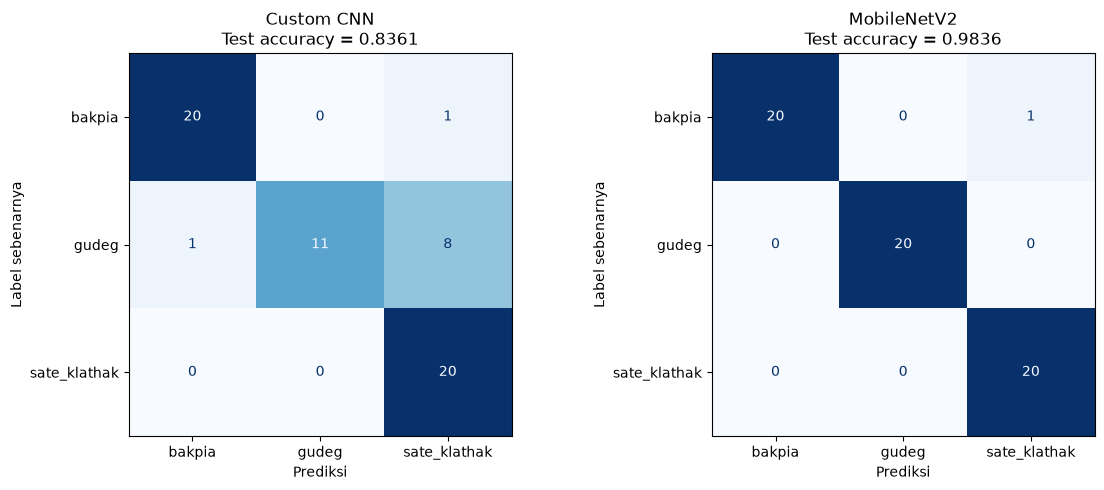

jumlah  benar_Custom CNN  \
kelas        asal                                              
bakpia       FUJIFILM X-T30 III         21                20   
gudeg        internet                    8                 5   
             samsung Galaxy A35 5G      12                 6   
sate_klathak FUJIFILM X-T30 III          3                 3   
             samsung Galaxy A35 5G      17                17   

                                    benar_MobileNetV2  
kelas        asal                                      
bakpia       FUJIFILM X-T30 III                    20  
gudeg        internet                               8  
             samsung Galaxy A35 5G                 12  
sate_klathak FUJIFILM X-T30 III                     3  
             samsung Galaxy A35 5G                 17

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# 9a. Prediksi test set (SATU KALI, model sudah dikunci di langkah 8)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
hasil = {}
for name, model in MODELS.items():
    t0 = time.time()
    probs = model.predict(test_ds, verbose=0)
    t_inf = time.time() - t0
    y_pred = probs.argmax(axis=1)
    hasil[name] = {"probs": probs, "y_pred": y_pred, "waktu_inferensi": t_inf}

    print(f"\n==================== {name} ====================")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    rep = pd.DataFrame(classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                             digits=4, output_dict=True)).T
    rep.to_csv(OUT / f"classification_report_{name.lower().replace(' ', '_')}.csv")

# 9b. Confusion matrix kedua model
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, r) in zip(axes, hasil.items()):
    cm = confusion_matrix(y_true, r["y_pred"], labels=range(NUM_CLASSES))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\nTest accuracy = {accuracy_score(y_true, r['y_pred']):.4f}")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya")
plt.tight_layout(); plt.savefig(OUT / "confusion_matrix.png", dpi=150); plt.show()

# 9c. Akurasi test per asal foto (internet / perangkat), dari manifest
man = pd.read_csv(MANIFEST)
man = man[man.split == "test"].set_index(["cls", "final_name"])
asal = [("internet" if man.loc[(CLASS_NAMES[t], f), "source"] == "internet" else man.loc[(CLASS_NAMES[t], f), "device"])
        for t, f in zip(y_true, TEST_FILES)]
per_asal = pd.DataFrame({"kelas": [CLASS_NAMES[t] for t in y_true], "asal": asal})
for name, r in hasil.items():
    per_asal[name] = (r["y_pred"] == y_true)
tabel_asal = per_asal.groupby(["kelas", "asal"]).agg(jumlah=("asal", "size"),
                                                    **{f"benar_{n}": (n, "sum") for n in hasil})
display(tabel_asal)

## 10. Tabel perbandingan kinerja kedua model
Menggabungkan efisiensi (parameter, epoch, waktu) dan performa test (accuracy, precision, recall, F1)
sesuai ketentuan evaluasi poin 5–6.

In [19]:
from sklearn.metrics import precision_recall_fscore_support

waktu_training = {"Custom CNN": time_cnn, "MobileNetV2": time_mnv2}
param_dilatih = {"Custom CNN": f"{cnn_final.count_params():,}",
                 "MobileNetV2": f"{mnv2_final.layers[-1].count_params():,} (fase 1) / {n_param_dilatih:,} (fase 2)"}

kolom = {}
for name, r in hasil.items():
    h = hist[name]
    best = int(h.val_loss.idxmin())
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, r["y_pred"], average="macro", zero_division=0)
    rec_kelas = precision_recall_fscore_support(y_true, r["y_pred"], labels=range(NUM_CLASSES), zero_division=0)[1]
    kolom[name] = {
        "Total parameter": f"{MODELS[name].count_params():,}",
        "Parameter dilatih": param_dilatih[name],
        "Epoch dijalankan / terbaik": f"{len(h)} / {best}",
        "Waktu training (detik)": f"{waktu_training[name]:.1f}",
        "Waktu inferensi (ms/citra)": f"{1000 * r['waktu_inferensi'] / len(y_true):.1f}",
        "Val accuracy (epoch terbaik)": f"{h.val_accuracy[best]:.4f}",
        "Test accuracy": f"{(r['y_pred'] == y_true).mean():.4f}",
        "Precision (macro)": f"{prec:.4f}",
        "Recall (macro)": f"{rec:.4f}",
        "F1-score (macro)": f"{f1:.4f}",
        **{f"Recall {c}": f"{v:.4f}" for c, v in zip(CLASS_NAMES, rec_kelas)},
    }

tabel_perbandingan = pd.DataFrame(kolom)
tabel_perbandingan.to_csv(OUT / "tabel_perbandingan.csv")
display(tabel_perbandingan)

,Custom CNN,MobileNetV2
Total parameter,"249,283","2,261,827"
Parameter dilatih,"249,283","3,843 (fase 1) / 1,865,283 (fase 2)"
Epoch dijalankan / terbaik,85 / 70,60 / 58
Waktu training (detik),251.3,211.2
Waktu inferensi (ms/citra),4.7,25.9
Val accuracy (epoch terbaik),0.9322,1.0000
Test accuracy,0.8361,0.9836
Precision (macro),0.8807,0.9841
Recall (macro),0.8341,0.9841
F1-score (macro),0.8261,0.9837


## 11. Contoh citra yang berhasil dan gagal diklasifikasikan
- Baris pertama: 2 contoh benar per kelas (dipilih acak dengan seed)
- Baris berikutnya: **semua** citra yang salah, lengkap dengan label, prediksi, keyakinan, dan asal foto
- Seluruh prediksi test disimpan ke `prediksi_test.csv`

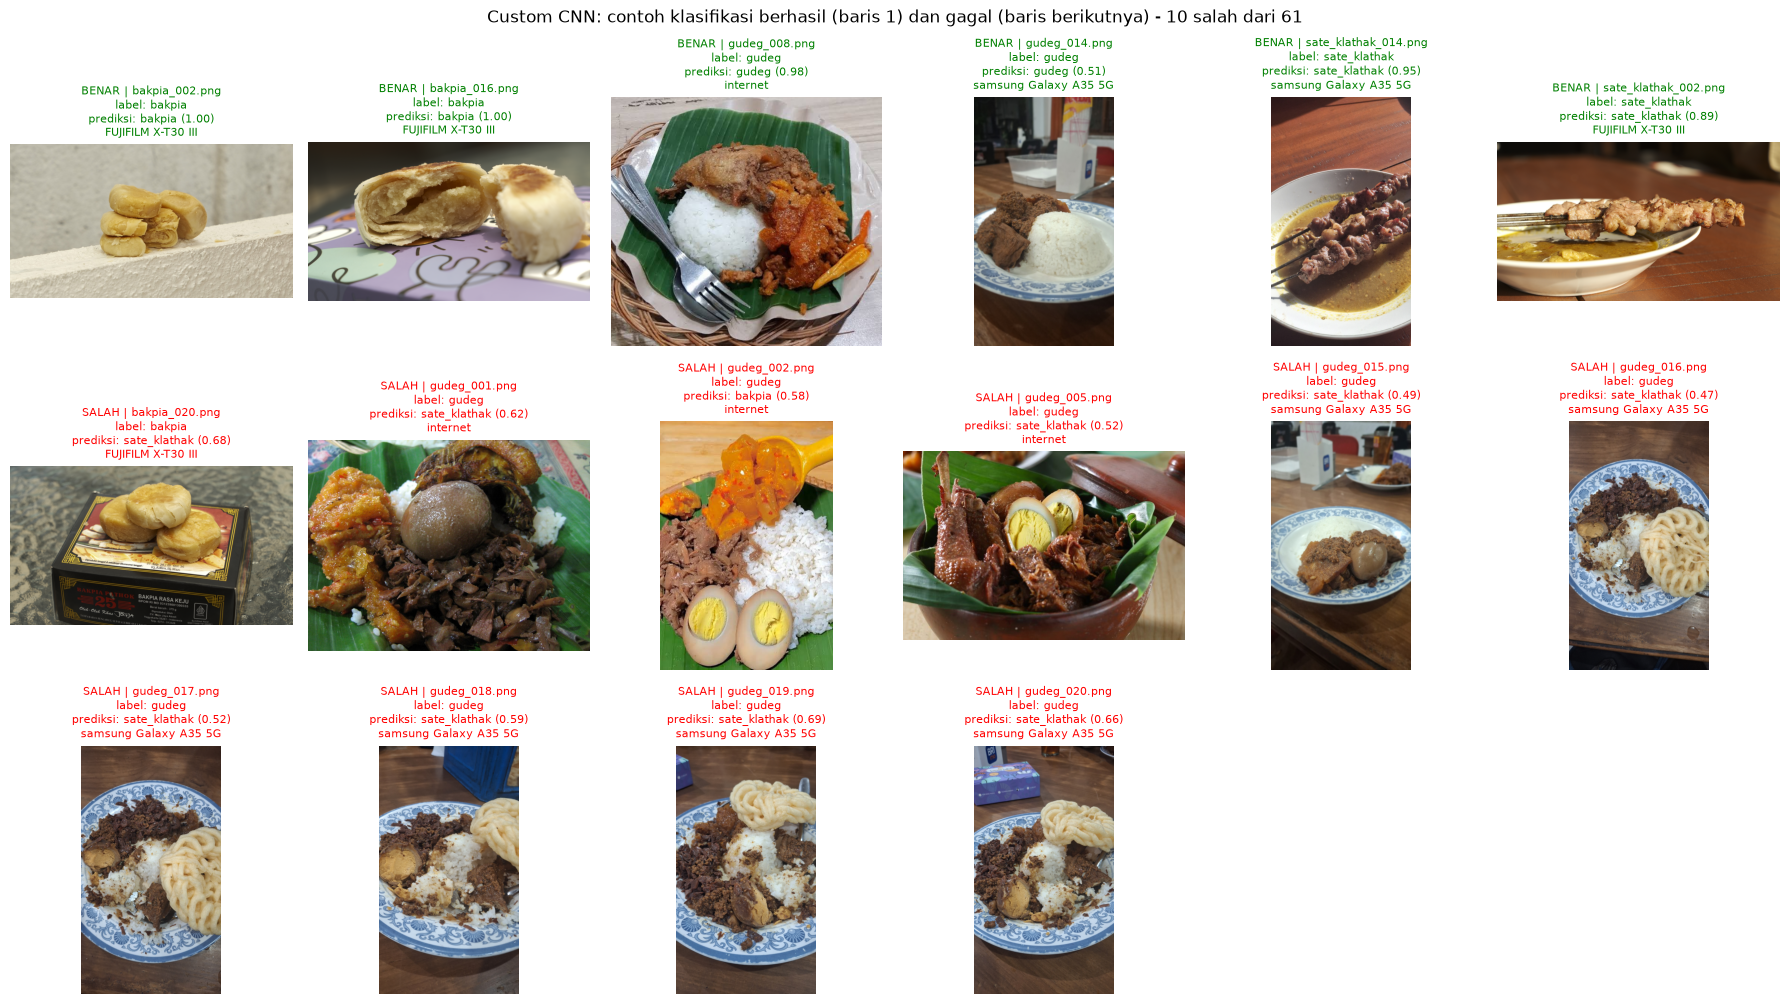

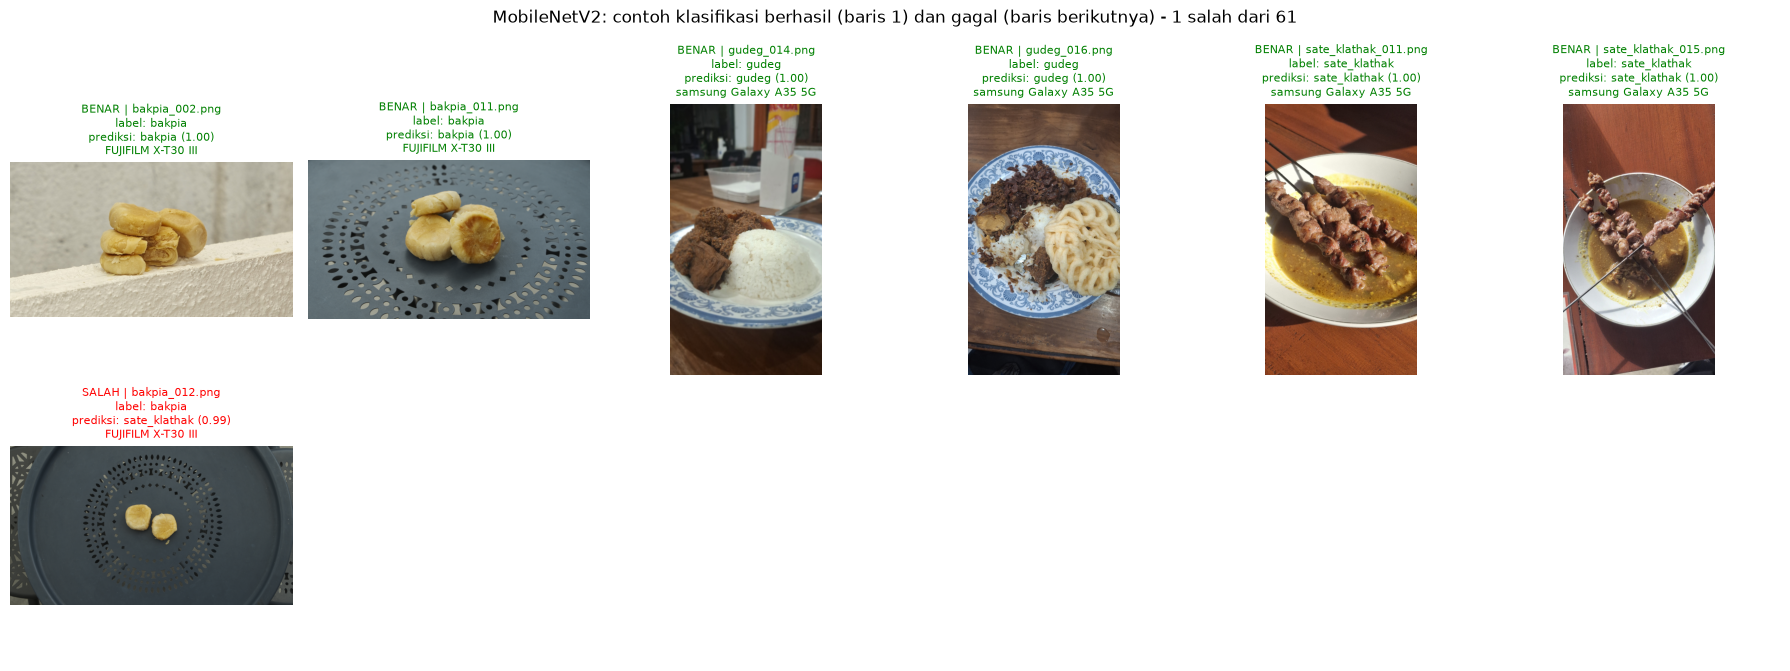

Daftar citra yang salah:


,file,label,asal,prediksi_Custom CNN,keyakinan_Custom CNN,prediksi_MobileNetV2,keyakinan_MobileNetV2
11,bakpia_012.png,bakpia,FUJIFILM X-T30 III,bakpia,0.9159,sate_klathak,0.9892
19,bakpia_020.png,bakpia,FUJIFILM X-T30 III,sate_klathak,0.6764,bakpia,0.9919
21,gudeg_001.png,gudeg,internet,sate_klathak,0.6204,gudeg,1.0000
22,gudeg_002.png,gudeg,internet,bakpia,0.5832,gudeg,0.9049
25,gudeg_005.png,gudeg,internet,sate_klathak,0.5171,gudeg,0.8370
35,gudeg_015.png,gudeg,samsung Galaxy A35 5G,sate_klathak,0.4886,gudeg,0.9948
36,gudeg_016.png,gudeg,samsung Galaxy A35 5G,sate_klathak,0.4747,gudeg,0.9958
37,gudeg_017.png,gudeg,samsung Galaxy A35 5G,sate_klathak,0.5211,gudeg,0.9819
38,gudeg_018.png,gudeg,samsung Galaxy A35 5G,sate_klathak,0.5897,gudeg,0.9748
39,gudeg_019.png,gudeg,samsung Galaxy A35 5G,sate_klathak,0.6879,gudeg,0.8993


In [20]:
# 11a. Simpan semua prediksi test (untuk lampiran dan analisis)
prediksi = pd.DataFrame({"file": TEST_FILES, "label": [CLASS_NAMES[t] for t in y_true], "asal": asal})
for name, r in hasil.items():
    prediksi[f"prediksi_{name}"] = [CLASS_NAMES[p] for p in r["y_pred"]]
    prediksi[f"keyakinan_{name}"] = r["probs"].max(axis=1).round(4)
prediksi.to_csv(OUT / "prediksi_test.csv", index=False)

# 11b. Contoh benar (2 per kelas, acak) dan SEMUA yang salah, per model
from PIL import Image
rng = np.random.default_rng(SEED)

def tampilkan_contoh(name, r, ncols=6):
    benar = []
    for k in range(NUM_CLASSES):
        idx = np.where((y_true == k) & (r["y_pred"] == y_true))[0]
        benar += list(rng.choice(idx, size=min(2, len(idx)), replace=False))
    salah = list(np.where(r["y_pred"] != y_true)[0])

    n_rows = 1 + max(1, int(np.ceil(len(salah) / ncols)))
    fig, axes = plt.subplots(n_rows, ncols, figsize=(3 * ncols, 3.4 * n_rows))
    for ax in axes.ravel():
        ax.axis("off")
    for j, i in enumerate(benar):
        ax = axes[0, j]
        ax.imshow(Image.open(SPLIT / "test" / CLASS_NAMES[y_true[i]] / TEST_FILES[i]))
        ax.set_title(f"BENAR | {TEST_FILES[i]}\nlabel: {CLASS_NAMES[y_true[i]]}\n"
                     f"prediksi: {CLASS_NAMES[r['y_pred'][i]]} ({r['probs'][i].max():.2f})\n{asal[i]}",
                     fontsize=8, color="green")
    if not salah:
        axes[1, 0].text(0, 0.5, "Tidak ada citra yang salah diklasifikasikan", fontsize=11)
    for j, i in enumerate(salah):
        ax = axes[1 + j // ncols, j % ncols]
        ax.imshow(Image.open(SPLIT / "test" / CLASS_NAMES[y_true[i]] / TEST_FILES[i]))
        ax.set_title(f"SALAH | {TEST_FILES[i]}\nlabel: {CLASS_NAMES[y_true[i]]}\n"
                     f"prediksi: {CLASS_NAMES[r['y_pred'][i]]} ({r['probs'][i].max():.2f})\n{asal[i]}",
                     fontsize=8, color="red")
    fig.suptitle(f"{name}: contoh klasifikasi berhasil (baris 1) dan gagal (baris berikutnya) "
                 f"- {len(salah)} salah dari {len(y_true)}", fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT / f"contoh_prediksi_{name.lower().replace(' ', '_')}.png", dpi=150)
    plt.show()

for name, r in hasil.items():
    tampilkan_contoh(name, r)

print("Daftar citra yang salah:")
salah_semua = prediksi[(prediksi.label != prediksi["prediksi_Custom CNN"]) | (prediksi.label != prediksi["prediksi_MobileNetV2"])]
display(salah_semua)

## 12. Penyimpanan model 
Model terbaik disimpan dalam format Keras (`.keras`) di `outputs/modelling/`.
`model_info.json` mencatat urutan kelas, format input, dan versi TensorFlow.
Sel ini juga menguji bahwa kedua model dapat dimuat ulang dan dipakai memprediksi.

In [22]:
import json
info = {
    "class_names": CLASS_NAMES,                       # indeks 0, 1, 2 -> nama kelas
    "input": f"citra RGB {IMG_SIZE[0]}x{IMG_SIZE[1]}, piksel 0-255 (normalisasi sudah di dalam model)",
    "tensorflow": tf.__version__,
    "models": {"Custom CNN": "custom_cnn_best.keras", "MobileNetV2": "mobilenetv2_best.keras"},
}
with open(OUT / "model_info.json", "w") as f:
    json.dump(info, f, indent=2)

# ambil ulang dari file lalu prediksi satu foto
path = SPLIT / "test" / "gudeg" / "gudeg_004.png"
img = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
arr = tf.image.resize(img, IMG_SIZE)[None, ...]           # resize sama persis dengan image_dataset_from_directory
for name, file in info["models"].items():
    m = tf.keras.models.load_model(OUT / file)
    p = m.predict(arr, verbose=0)[0]
    size_mb = (OUT / file).stat().st_size / 1e6
    print(f"{name:12s} | {file} ({size_mb:.1f} MB) | prediksi: {CLASS_NAMES[p.argmax()]} {p.round(3)}")

Custom CNN   | custom_cnn_best.keras (3.1 MB) | prediksi: gudeg [0.    0.504 0.496]
MobileNetV2  | mobilenetv2_best.keras (24.6 MB) | prediksi: gudeg [0. 1. 0.]
